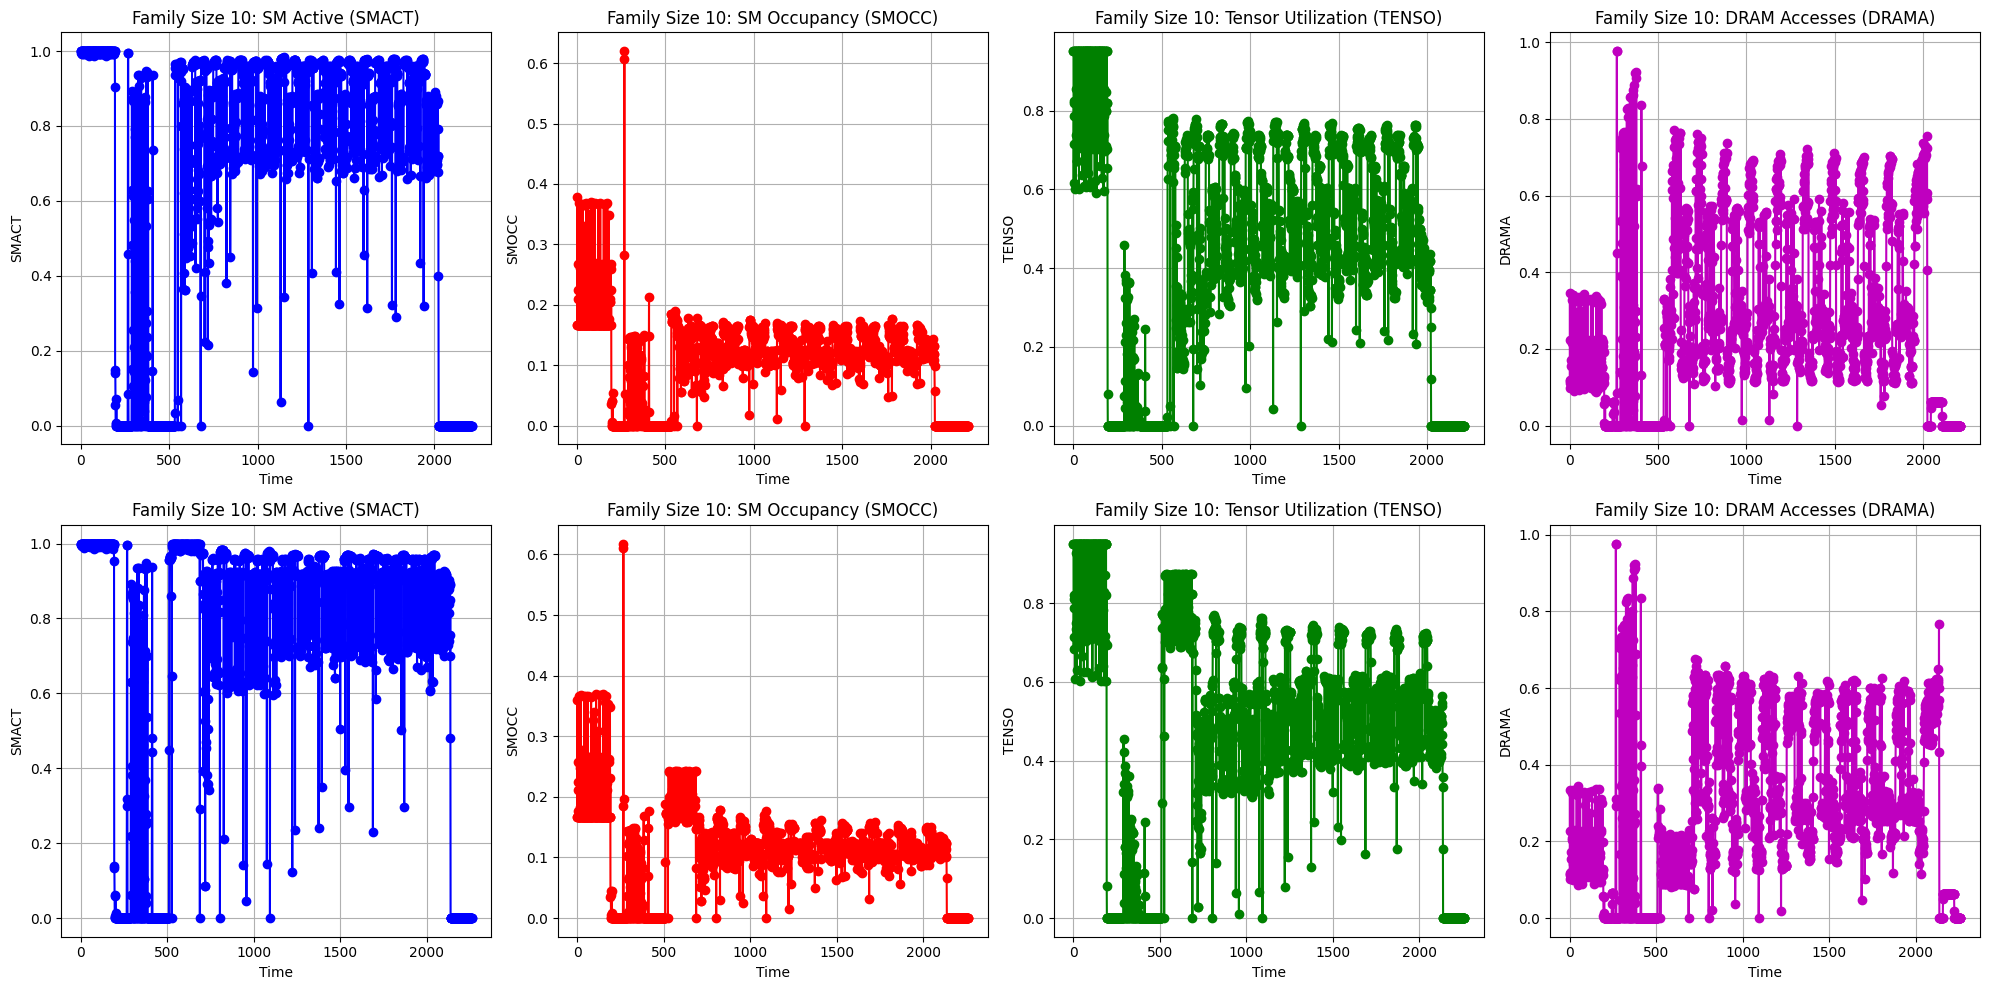

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re

files = [".out_10_100_not_random", ".out_10_100_random"]

fig, axes = plt.subplots(nrows=len(files), ncols=4, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, file_path in enumerate(files):
    match = re.search(r"(\d+)", file_path)
    batch_size = match.group(1) if match else "?"
    data = []
    with open(file_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                parts = line.split()
                if len(parts) >= 4 and len(parts) <= 7:
                    smact = parts[2]
                    smocc = parts[3]
                    tenso = parts[4]
                    drama = parts[5]
                    try:
                        data.append((float(smact), float(smocc), float(tenso), float(drama)))
                    except ValueError:
                        continue

    df = pd.DataFrame(data, columns=["SMACT", "SMOCC", "TENSO", "DRAMA"])

    # --- Plot SMACT ---
    ax1 = axes[i, 0]
    ax1.plot(df["SMACT"], marker='o', linestyle='-', color='b')
    ax1.set_title(f"Family Size {batch_size}: SM Active (SMACT)")
    ax1.set_xlabel("Time")
    ax1.set_ylabel("SMACT")
    ax1.grid(True)

    # --- Plot SMOCC ---
    ax2 = axes[i, 1]
    ax2.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
    ax2.set_title(f"Family Size {batch_size}: SM Occupancy (SMOCC)")
    ax2.set_xlabel("Time")
    ax2.set_ylabel("SMOCC")
    ax2.grid(True)

    # --- Plot TENSO ---
    ax3 = axes[i, 2]
    ax3.plot(df["TENSO"], marker='o', linestyle='-', color='g')
    ax3.set_title(f"Family Size {batch_size}: Tensor Utilization (TENSO)")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("TENSO")
    ax3.grid(True)  

    # --- Plot DRAMA ---
    ax4 = axes[i, 3]
    ax4.plot(df["DRAMA"], marker='o', linestyle='-', color='m')
    ax4.set_title(f"Family Size {batch_size}: DRAM Accesses (DRAMA)")
    ax4.set_xlabel("Time")
    ax4.set_ylabel("DRAMA")
    ax4.grid(True)
plt.tight_layout()
plt.show()
# plt.savefig("../../results/smact_smocc_tenso_family_sizes_batch_size_500.png")
# plt.savefig("../../results/smact_smocc_batch_sizes.png")

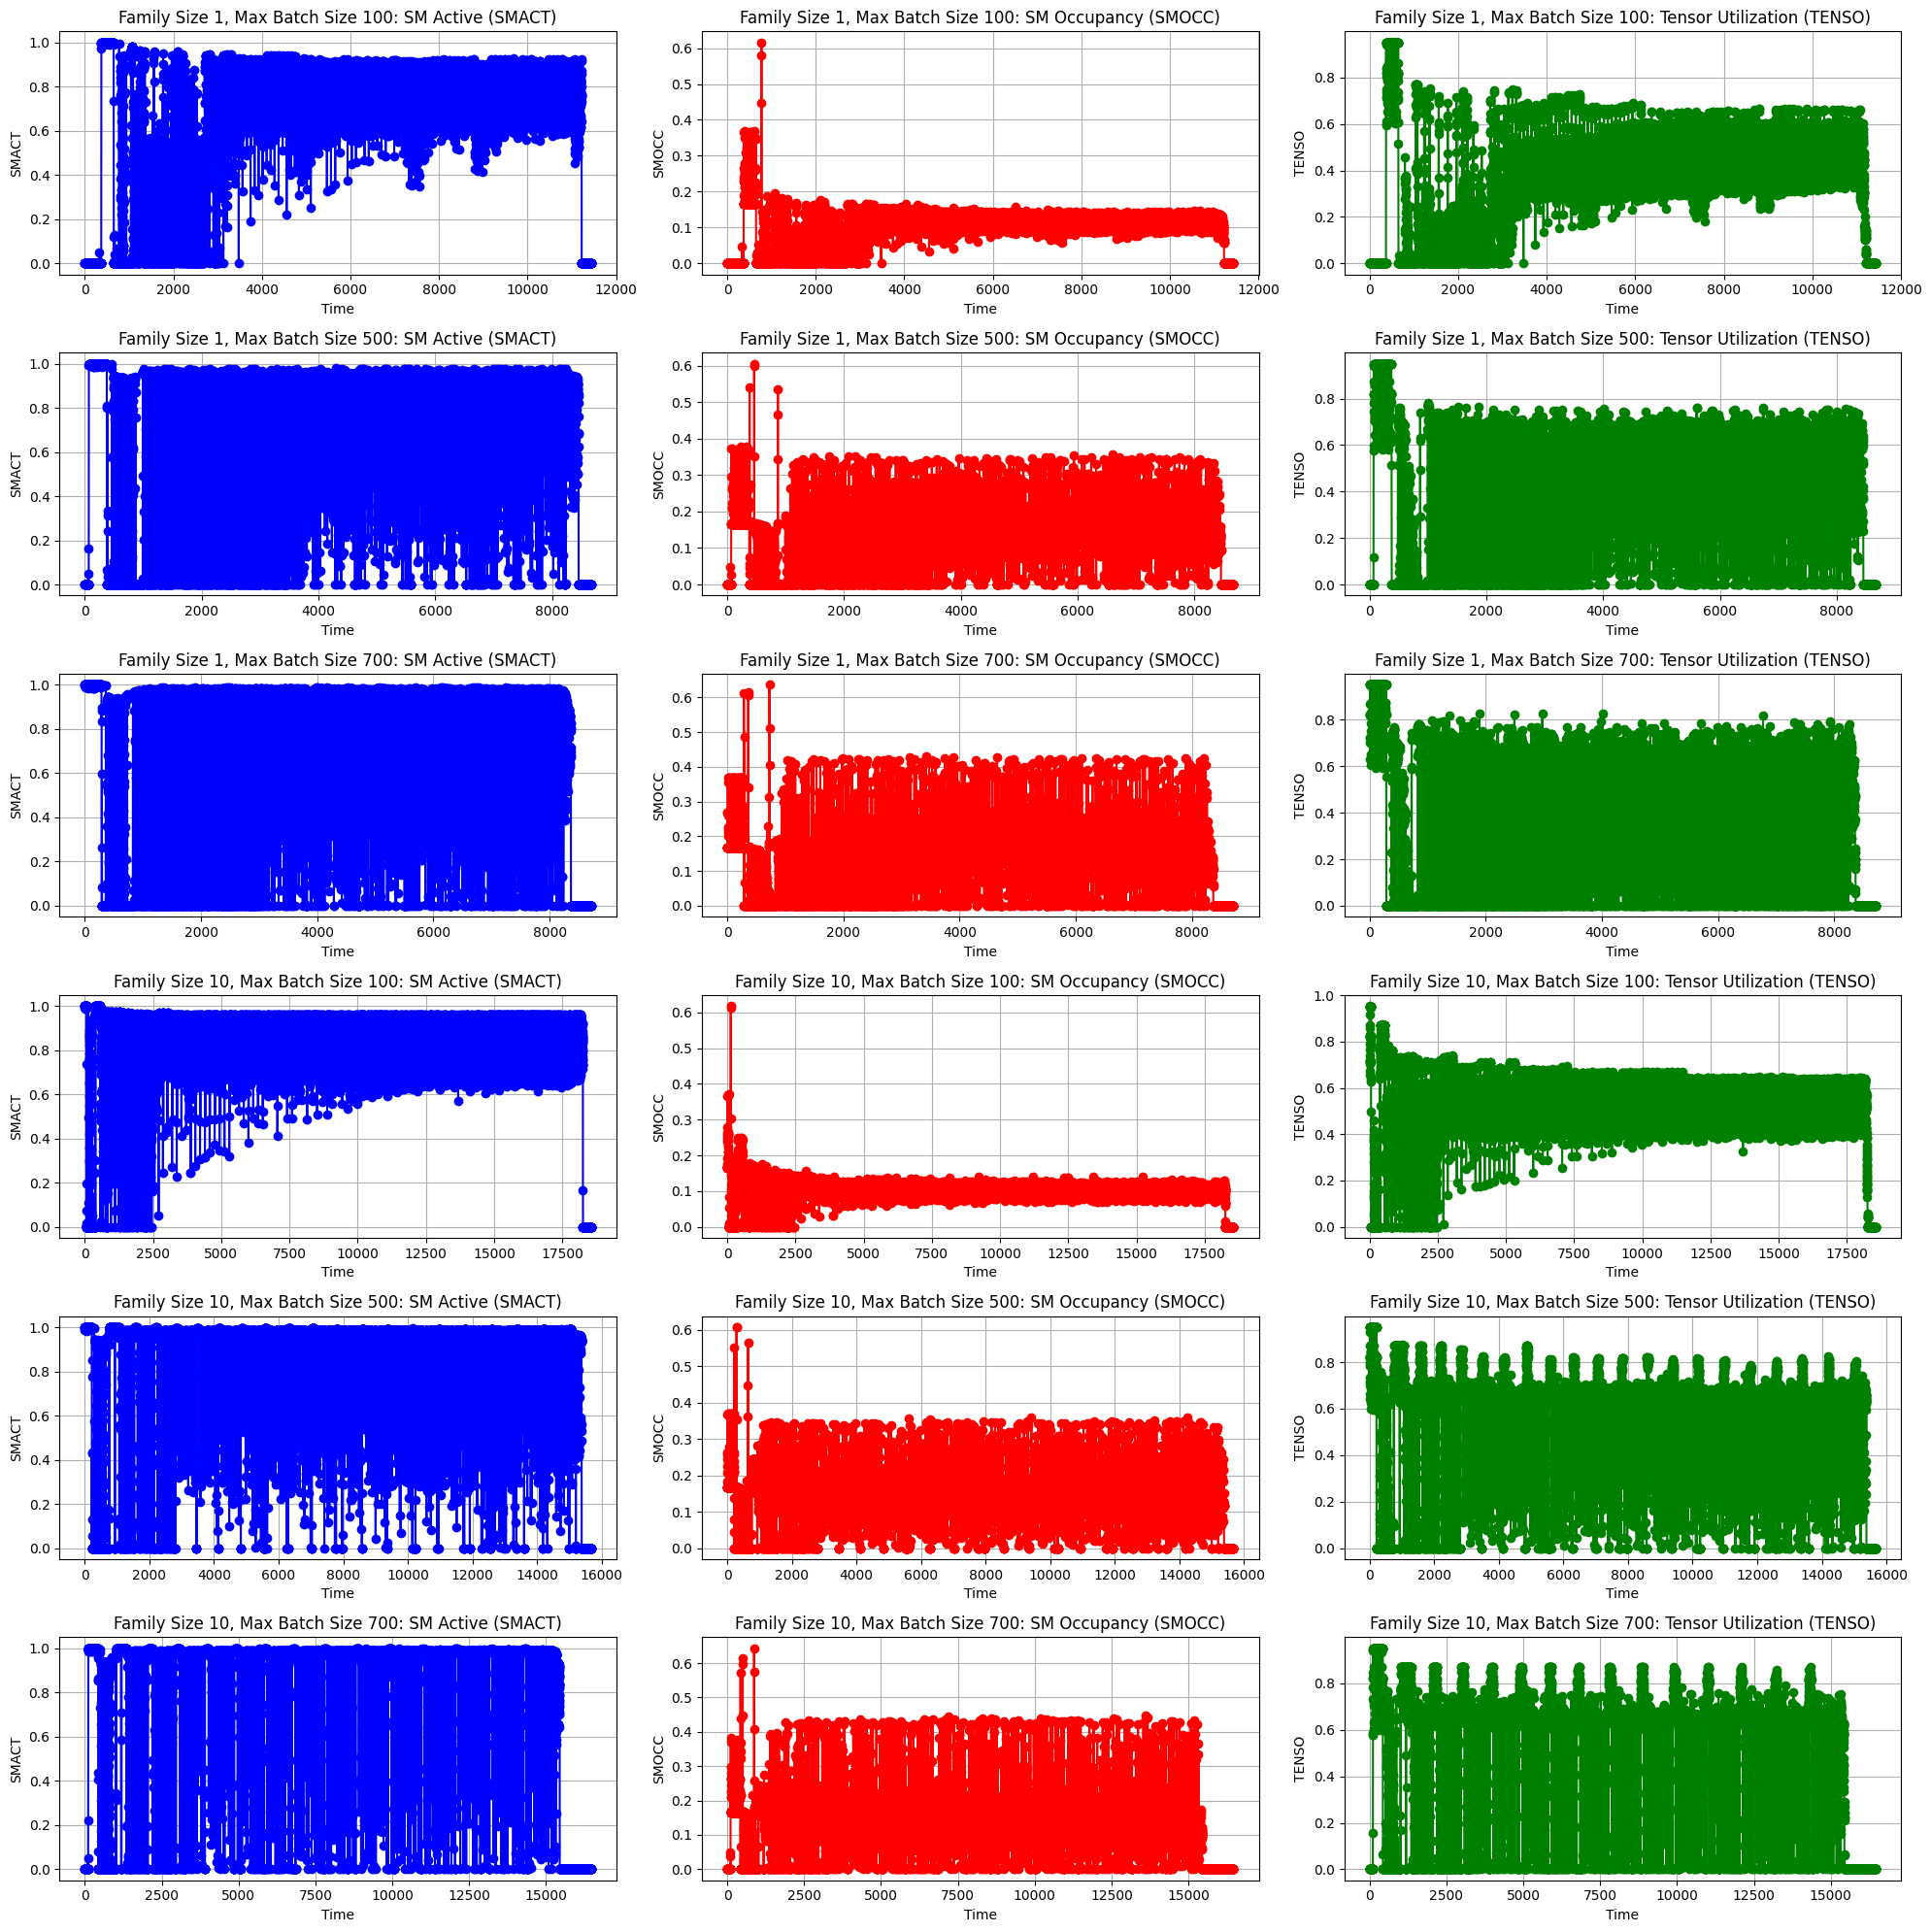

<Figure size 640x480 with 0 Axes>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import re

files = [".out_1_100", ".out_1_500", ".out_1_700", ".out_10_100", ".out_10_500", ".out_10_700"]

fig, axes = plt.subplots(nrows=len(files), ncols=3, figsize=(20,20))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, file_path in enumerate(files):
    # Extract batch size (last number in the filename)
    match = re.search(r"(\d+)", file_path)
    family_size = match.group(1) if match else "?"
    batch_size = re.search(r"_(\d+)$", file_path).group(1) if re.search(r"_(\d+)$", file_path) else "?"

    data = []
    with open(file_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                parts = line.split()
                if len(parts) >= 5 and len(parts) <= 7:
                    smact = parts[2]
                    smocc = parts[3]
                    tenso = parts[4]
                    try:
                        data.append((float(smact), float(smocc), float(tenso)))
                    except ValueError:
                        continue

    df = pd.DataFrame(data, columns=["SMACT", "SMOCC", "TENSO"])

    ax1 = axes[i, 0]
    ax1.plot(df["SMACT"], marker='o', linestyle='-', color='b')
    ax1.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: SM Active (SMACT)")
    ax1.set_xlabel("Time")
    ax1.set_ylabel("SMACT")
    ax1.grid(True)

    ax2 = axes[i, 1]
    ax2.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
    ax2.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: SM Occupancy (SMOCC)")
    ax2.set_xlabel("Time")
    ax2.set_ylabel("SMOCC")
    ax2.grid(True)

    ax3 = axes[i, 2]
    ax3.plot(df["TENSO"], marker='o', linestyle='-', color='g')
    ax3.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: Tensor Utilization (TENSO)")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("TENSO")
    ax3.grid(True)  
plt.tight_layout()
plt.show()
plt.savefig("../../results/smact_smocc_tenso_different_family_batches.png")

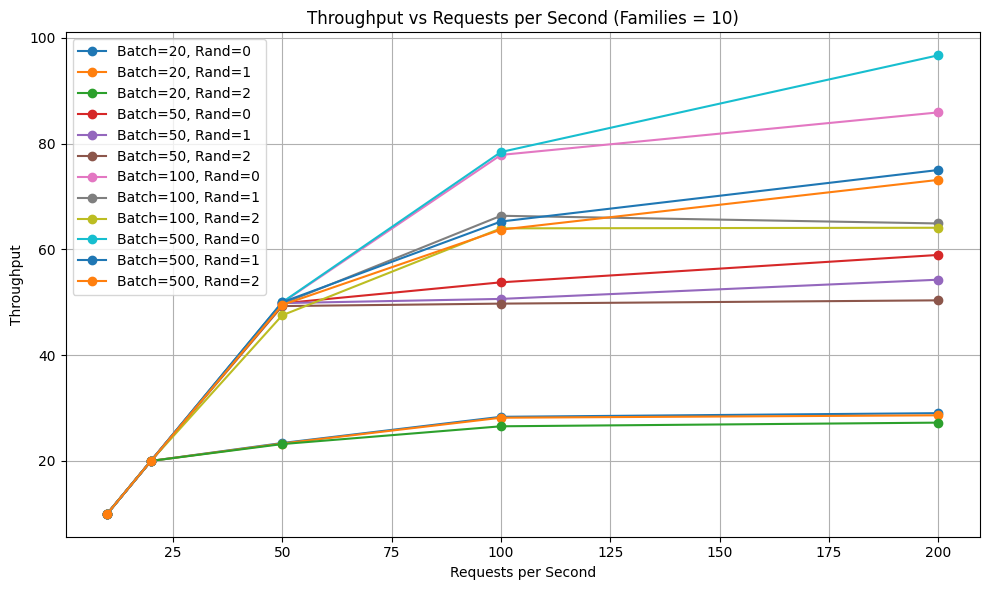

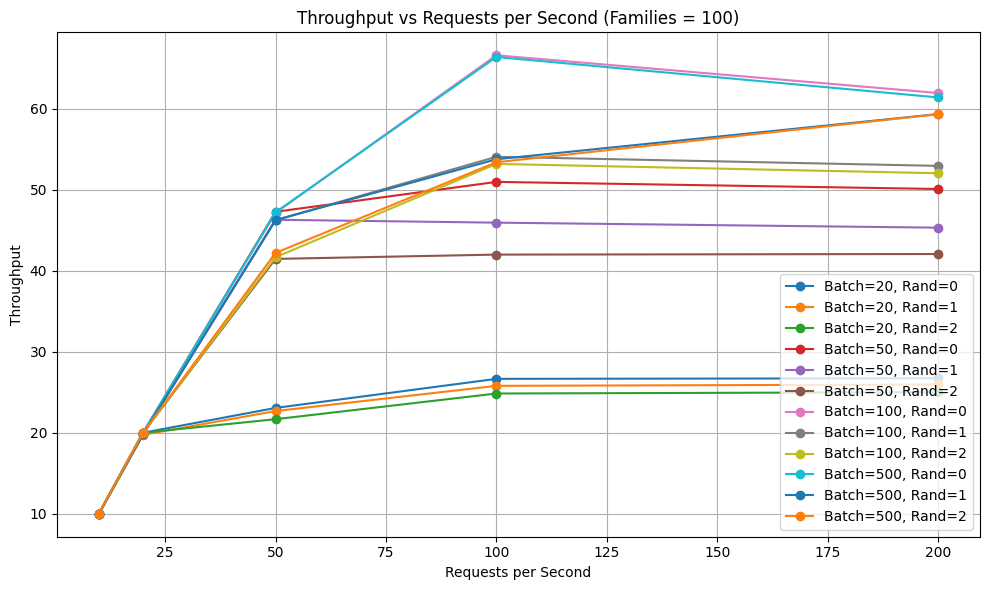

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- READ AND PARSE ----------
data = []
pattern = re.compile(
    r"Throughput Test with (\d+) families, (\d+) req/sec and max_batch_size of (\d+) \(randomness: (\d+)\): ([\d\.]+)"
)

tuple_to_throughput = {}

with open("vllm_multiple_families_varying_workloads_output.txt") as f:
    for line in f:
        m = pattern.search(line)
        if m:
            families, req, batch, rand, value = m.groups()
            tuple_to_throughput[(int(families), int(req), int(batch), int(rand))] = float(value)
for (key, value) in tuple_to_throughput.items():
    families, req, batch, rand = key
    data.append({
        "families": families,
        "req_per_sec": req,
        "batch_size": batch,
        "randomness": rand,
        "throughput": value
    })

df = pd.DataFrame(data)

# ---------- PLOT: Separate for each number of families ----------
for families, df_fam in df.groupby("families"):
    plt.figure(figsize=(10, 6))
    for (batch, rand), group in df_fam.groupby(["batch_size", "randomness"]):
        group = group.sort_values("req_per_sec")
        plt.plot(group["req_per_sec"], group["throughput"], marker="o", label=f"Batch={batch}, Rand={rand}")

    plt.xlabel("Requests per Second")
    plt.ylabel("Throughput")
    plt.title(f"Throughput vs Requests per Second (Families = {families})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


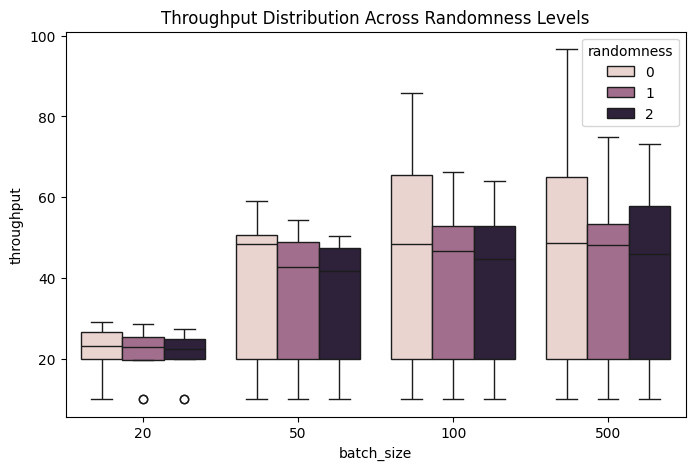

In [6]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="batch_size", y="throughput", hue="randomness")
plt.title("Throughput Distribution Across Randomness Levels")
plt.show()


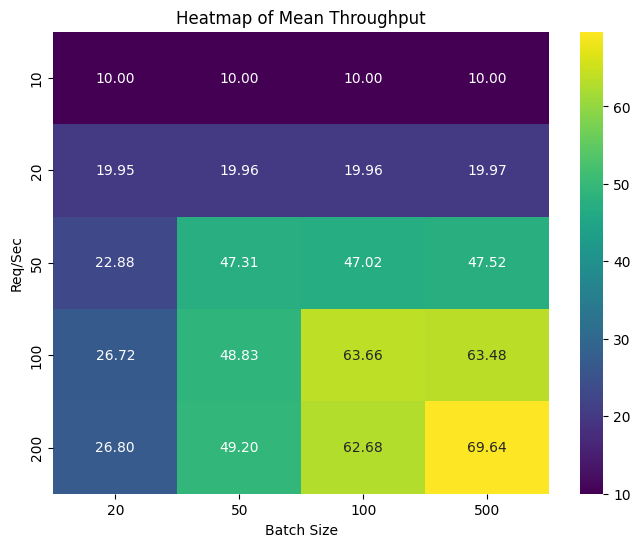

In [7]:
pivot = df.groupby(["req_per_sec", "batch_size"])["throughput"].mean().unstack()
plt.figure(figsize=(8,6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis")
plt.title("Heatmap of Mean Throughput")
plt.ylabel("Req/Sec")
plt.xlabel("Batch Size")
plt.show()
